# IPP Practical File 2

Swanand Wirkar 20251051 BDA

## Problem Statement

Problem 1: Comparative Edge Detection on Natural Images
Load an outdoor natural image (trees, buildings, roads). Apply Sobel, Laplacian, and Canny edge detection. Compare the outputs and explain which operator captures the most meaningful edges and why.

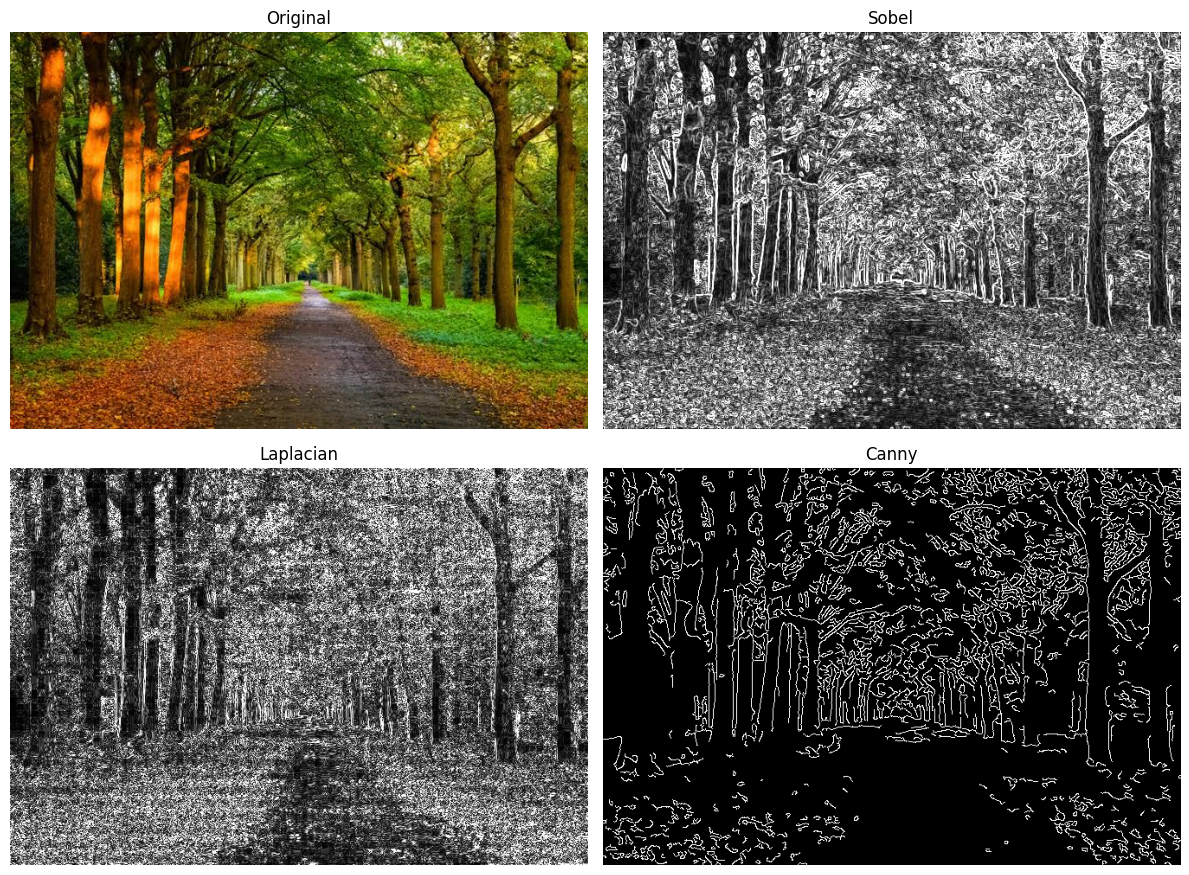

Sobel estimates first-order gradients and highlights edge strength. Laplacian responds in all directions but is noise-sensitive. Canny combines smoothing, non-maximum suppression and hysteresis thresholding, often producing thin, connected, meaningful edges. Results depend on the image and thresholds.


In [1]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("natural_image.jpg")
if image is None:
    raise FileNotFoundError("Place an outdoor image named natural_image.jpg in the notebook folder.")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
laplacian = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F, ksize=3))
canny = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 1.2), 80, 160)
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0,0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax[0,0].set_title("Original")
ax[0,1].imshow(sobel, cmap="gray"); ax[0,1].set_title("Sobel")
ax[1,0].imshow(laplacian, cmap="gray"); ax[1,0].set_title("Laplacian")
ax[1,1].imshow(canny, cmap="gray"); ax[1,1].set_title("Canny")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print("Sobel estimates first-order gradients and highlights edge strength. Laplacian responds in all directions but is noise-sensitive. Canny combines smoothing, non-maximum suppression and hysteresis thresholding, often producing thin, connected, meaningful edges. Results depend on the image and thresholds.")